# 04 · Cell-type composition — GSE216146

Do cell-type proportions differ between chemotherapy (cisplatin) and control (PBS) brains?

Method (propeller-style, Phipson et al. 2022): proportions per **sample** (the unit of replication; 3 vs 3),
arcsin-square-root transform, one linear model per cell type with `composition.formula` (`~ batch + condition`),
Benjamini-Hochberg FDR. With n = 3 per group and 3 residual degrees of freedom, results are **exploratory**.

**Input:** `results/03_annotated.h5ad` · **Output:** tables `results/tables/04_*`, plots `results/plots/04_*`.

Caveats (see `03_annotation`):
- Cell types in `downstream.exclude_cell_types` (low-quality microglia) are removed first.
- Proportions are relative: the very large choroid plexus fraction in D21-2750 (dissection variability) lowers every
  other proportion in that sample. The test is repeated after removing `composition.sensitivity_drop` and renormalizing.
- **Neurons: do not interpret the decrease.** QC removes 46 % of neurons in controls and 62 % in cisplatin (mt cut,
  see `01_qc`), and before QC their proportions barely differ. The neuron result here is mostly a QC effect.
- **Neuroblasts: robust.** They are already lower in every cisplatin sample before QC (authors' labels: 0.2–0.6 %
  vs 1.4–1.8 %), so the decrease is not caused by filtering (dissection can still contribute).

In [1]:
import gc
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import sc_utils as scu

cfg = scu.load_config(ROOT / "config.yaml")
p = cfg["composition"]
scu.setup_plotting()
p

{'formula': '~ batch + condition',
 'sensitivity_drop': ['Choroid plexus'],
 'fdr': 0.1}

In [2]:
adata = sc.read_h5ad(cfg["paths"]["results_dir"] / "03_annotated.h5ad")
drop = cfg["downstream"]["exclude_cell_types"]
print("excluded:", adata.obs["cell_type"].isin(drop).sum(), "cells of", drop)
adata = adata[~adata.obs["cell_type"].isin(drop)].copy()
adata.obs["cell_type"] = adata.obs["cell_type"].cat.remove_unused_categories()
obs = adata.obs
adata

excluded: 104 cells of ['Low-quality microglia']


AnnData object with n_obs × n_vars = 9728 × 19941
    obs: 'biosample', 'pathology', 'batch', 'doublet_score', 'predicted_doublet', 'MajorCellType', 'orig_celltype', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'condition', 'leiden_res_0.15', 'leiden_res_0.50', 'leiden_res_2.00', 'ct_label', 'ct_majority', 'ct_conf', 'ct_class', 'ct_majority_class', 'cell_type', 'cell_type_fine'
    var: 'mt', 'ribo', 'hb', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'MajorCellType_colors', 'batch_colors', 'biosample_colors', 'cell_type_colors', 'cell_type_fine_colors', 'condition_colors', 'ct_class_colors', 'hvg', 'leiden_res_0.15', 'leiden_res_0.15_colors', 'leiden_res_0.50', 'leiden_res_0.50_colors', 'leiden_res_2.00', 'leiden_res_2.00_colors', 'log1p', 'neighbors', 'pca', 'qc_colors', 'umap'
    obsm

## 1. Cells and proportions per sample

In [3]:
# Per-sample design table (one row per biosample)
meta = (obs[["biosample", "condition", "batch"]].drop_duplicates().set_index("biosample")
        .sort_values(["condition", "batch"]))
meta.index = meta.index.astype(str)
meta["condition"] = meta["condition"].cat.remove_unused_categories()
meta["batch"] = meta["batch"].astype(str)
sample_order = list(meta.index)

counts = pd.crosstab(obs["biosample"].astype(str), obs["cell_type"]).loc[sample_order]
props = counts.div(counts.sum(axis=1), axis=0)
counts.to_csv(cfg["paths"]["tables_dir"] / "04_cell_counts_per_sample.tsv", sep="\t")
props.round(4).to_csv(cfg["paths"]["tables_dir"] / "04_proportions_per_sample.tsv", sep="\t")
meta.join(counts.sum(axis=1).rename("cells"))

,condition,batch,cells
biosample,,,
D20-6407,Control,D20,966
D21-2746,Control,D21,2369
D21-2747,Control,D21,1636
D20-6409,Chemotherapy,D20,1556
D21-2750,Chemotherapy,D21,2302
D21-2751,Chemotherapy,D21,899


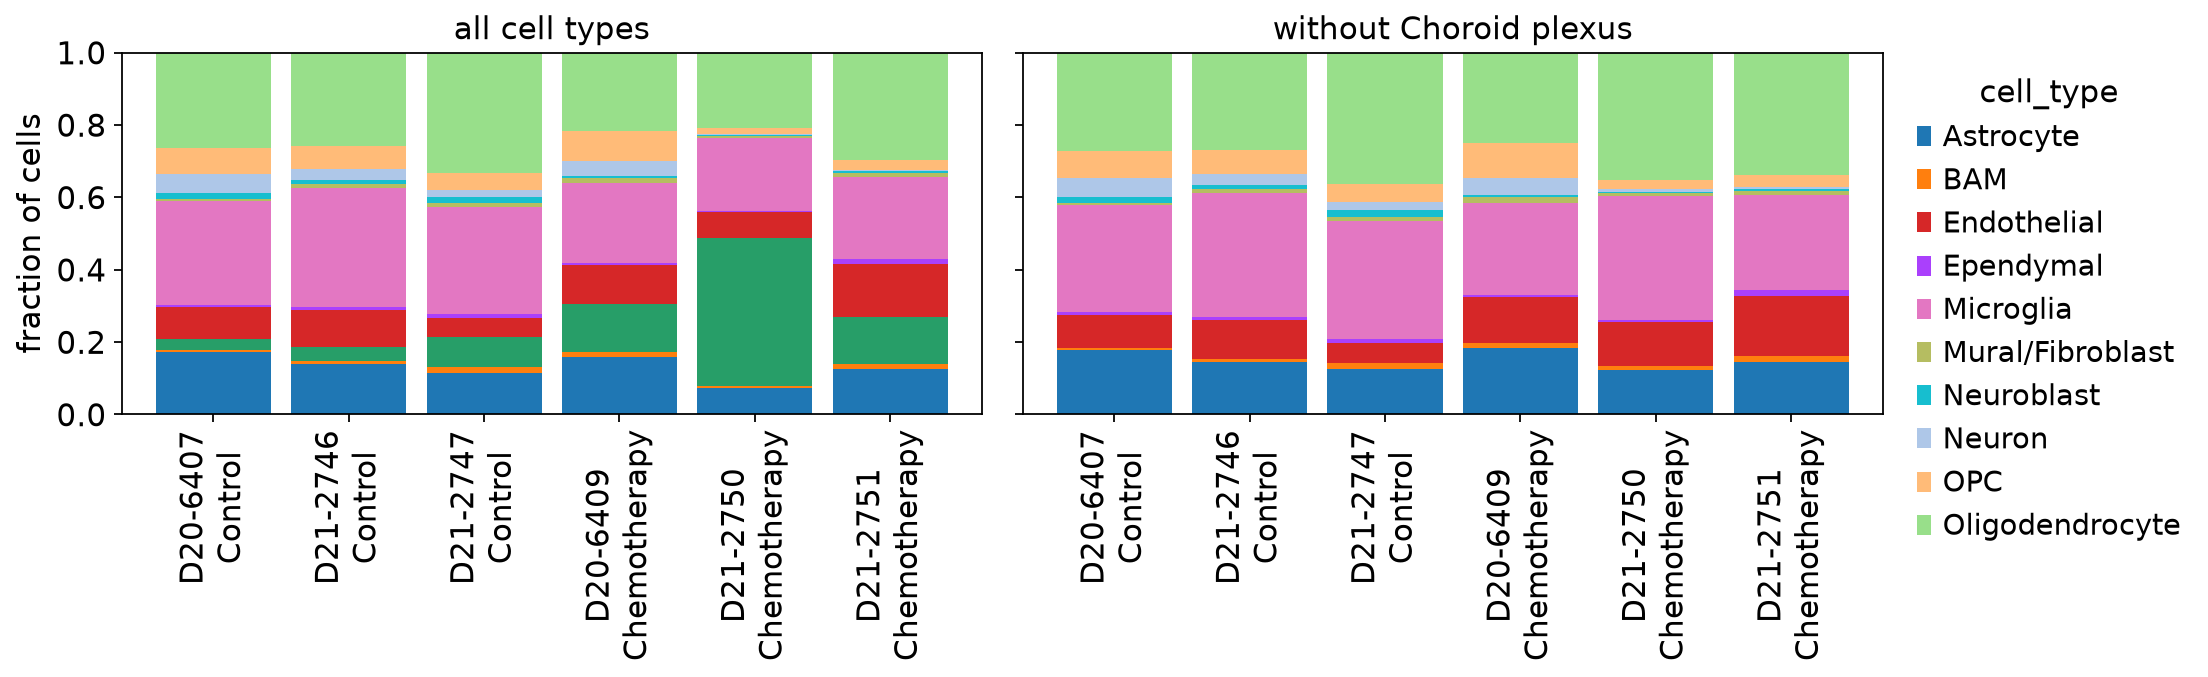

In [4]:
# Stacked bars per sample, with and without choroid plexus
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
colors = dict(zip(adata.obs["cell_type"].cat.categories, adata.uns["cell_type_colors"])) \
    if "cell_type_colors" in adata.uns and len(adata.uns["cell_type_colors"]) == adata.obs["cell_type"].cat.categories.size else None
for ax, (title, tab) in zip(axes, [("all cell types", props),
                                   (f"without {', '.join(p['sensitivity_drop'])}",
                                    counts.drop(columns=p["sensitivity_drop"]).pipe(lambda c: c.div(c.sum(axis=1), axis=0)))]):
    tab.plot(kind="bar", stacked=True, width=0.85, ax=ax, legend=False,
             color=[colors[c] for c in tab.columns] if colors else None)
    ax.set_xticklabels([f"{s}\n{meta.loc[s, 'condition']}" for s in tab.index], rotation=90)
    ax.set_title(title); ax.set_ylabel("fraction of cells"); ax.set_xlabel(""); ax.set_ylim(0, 1); ax.grid(False)
axes[1].legend(title="cell_type", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
fig.tight_layout()
scu.save_fig(fig, cfg, "04_stacked_proportions")
plt.show()

## 2. Composition test (`~ batch + condition`)

In [5]:
res_all = scu.composition_test(counts, meta, formula=p["formula"])
res_all.round(4)

,mean_prop_Control,mean_prop_Chemotherapy,log2_ratio,coef,pval,fdr
cell_type,,,,,,
Microglia,0.3049,0.2174,-0.4880,-0.0999,0.0112,0.1227
Neuroblast,0.0154,0.0042,-1.8658,-0.0615,0.0292,0.1593
Neuron,0.0333,0.0166,-1.0085,-0.0675,0.0434,0.1593
Choroid plexus,0.0507,0.2230,2.1369,0.2563,0.1136,0.3125
OPC,0.0610,0.0425,-0.5230,-0.0535,0.2385,0.5248
Oligodendrocyte,0.2849,0.2404,-0.2452,-0.0512,0.3195,0.5598
Astrocyte,0.1423,0.1197,-0.2501,-0.0362,0.3562,0.5598
Endothelial,0.0804,0.1087,0.4341,0.0480,0.4247,0.5839
Ependymal,0.0086,0.0076,-0.1802,-0.0103,0.6880,0.8409


In [6]:
# Sensitivity: remove choroid plexus and renormalize the remaining proportions
counts_wo = counts.drop(columns=p["sensitivity_drop"])
res_wo = scu.composition_test(counts_wo, meta, formula=p["formula"])
res_wo.round(4)

,mean_prop_Control,mean_prop_Chemotherapy,log2_ratio,coef,pval,fdr
cell_type,,,,,,
Neuroblast,0.0162,0.0051,-1.6751,-0.0577,0.0309,0.3094
Neuron,0.0349,0.0200,-0.8048,-0.0584,0.0717,0.3586
Endothelial,0.0842,0.1378,0.7101,0.0873,0.1184,0.3946
Microglia,0.3213,0.2866,-0.1653,-0.0385,0.2951,0.6431
OPC,0.0640,0.0516,-0.3123,-0.0362,0.3608,0.6431
Mural/Fibroblast,0.0086,0.0110,0.3573,0.0119,0.4250,0.6431
BAM,0.0108,0.0140,0.3641,0.0161,0.4502,0.6431
Oligodendrocyte,0.3013,0.3140,0.0594,0.0136,0.7444,0.9109
Ependymal,0.0091,0.0092,0.0160,-0.0030,0.8974,0.9109


In [7]:
cols = ["log2_ratio", "pval", "fdr"]
tag = "without_" + "_".join(p["sensitivity_drop"]).replace(" ", "_")
both = res_all[cols].add_suffix("_all").join(res_wo[cols].add_suffix(f"_{tag}"), how="left")
both.to_csv(cfg["paths"]["tables_dir"] / "04_composition_test.tsv", sep="\t")
both.round(3)

,log2_ratio_all,pval_all,fdr_all,log2_ratio_without_Choroid_plexus,pval_without_Choroid_plexus,fdr_without_Choroid_plexus
cell_type,,,,,,
Microglia,-0.488,0.011,0.123,-0.165,0.295,0.643
Neuroblast,-1.866,0.029,0.159,-1.675,0.031,0.309
Neuron,-1.008,0.043,0.159,-0.805,0.072,0.359
Choroid plexus,2.137,0.114,0.312,NaN,NaN,NaN
OPC,-0.523,0.239,0.525,-0.312,0.361,0.643
Oligodendrocyte,-0.245,0.319,0.560,0.059,0.744,0.911
Astrocyte,-0.250,0.356,0.560,0.014,0.911,0.911
Endothelial,0.434,0.425,0.584,0.710,0.118,0.395
Ependymal,-0.180,0.688,0.841,0.016,0.897,0.911


## 3. Per-sample proportions by condition

Each point is a sample (shape = batch). Shown without choroid plexus, since its size is driven by dissection.

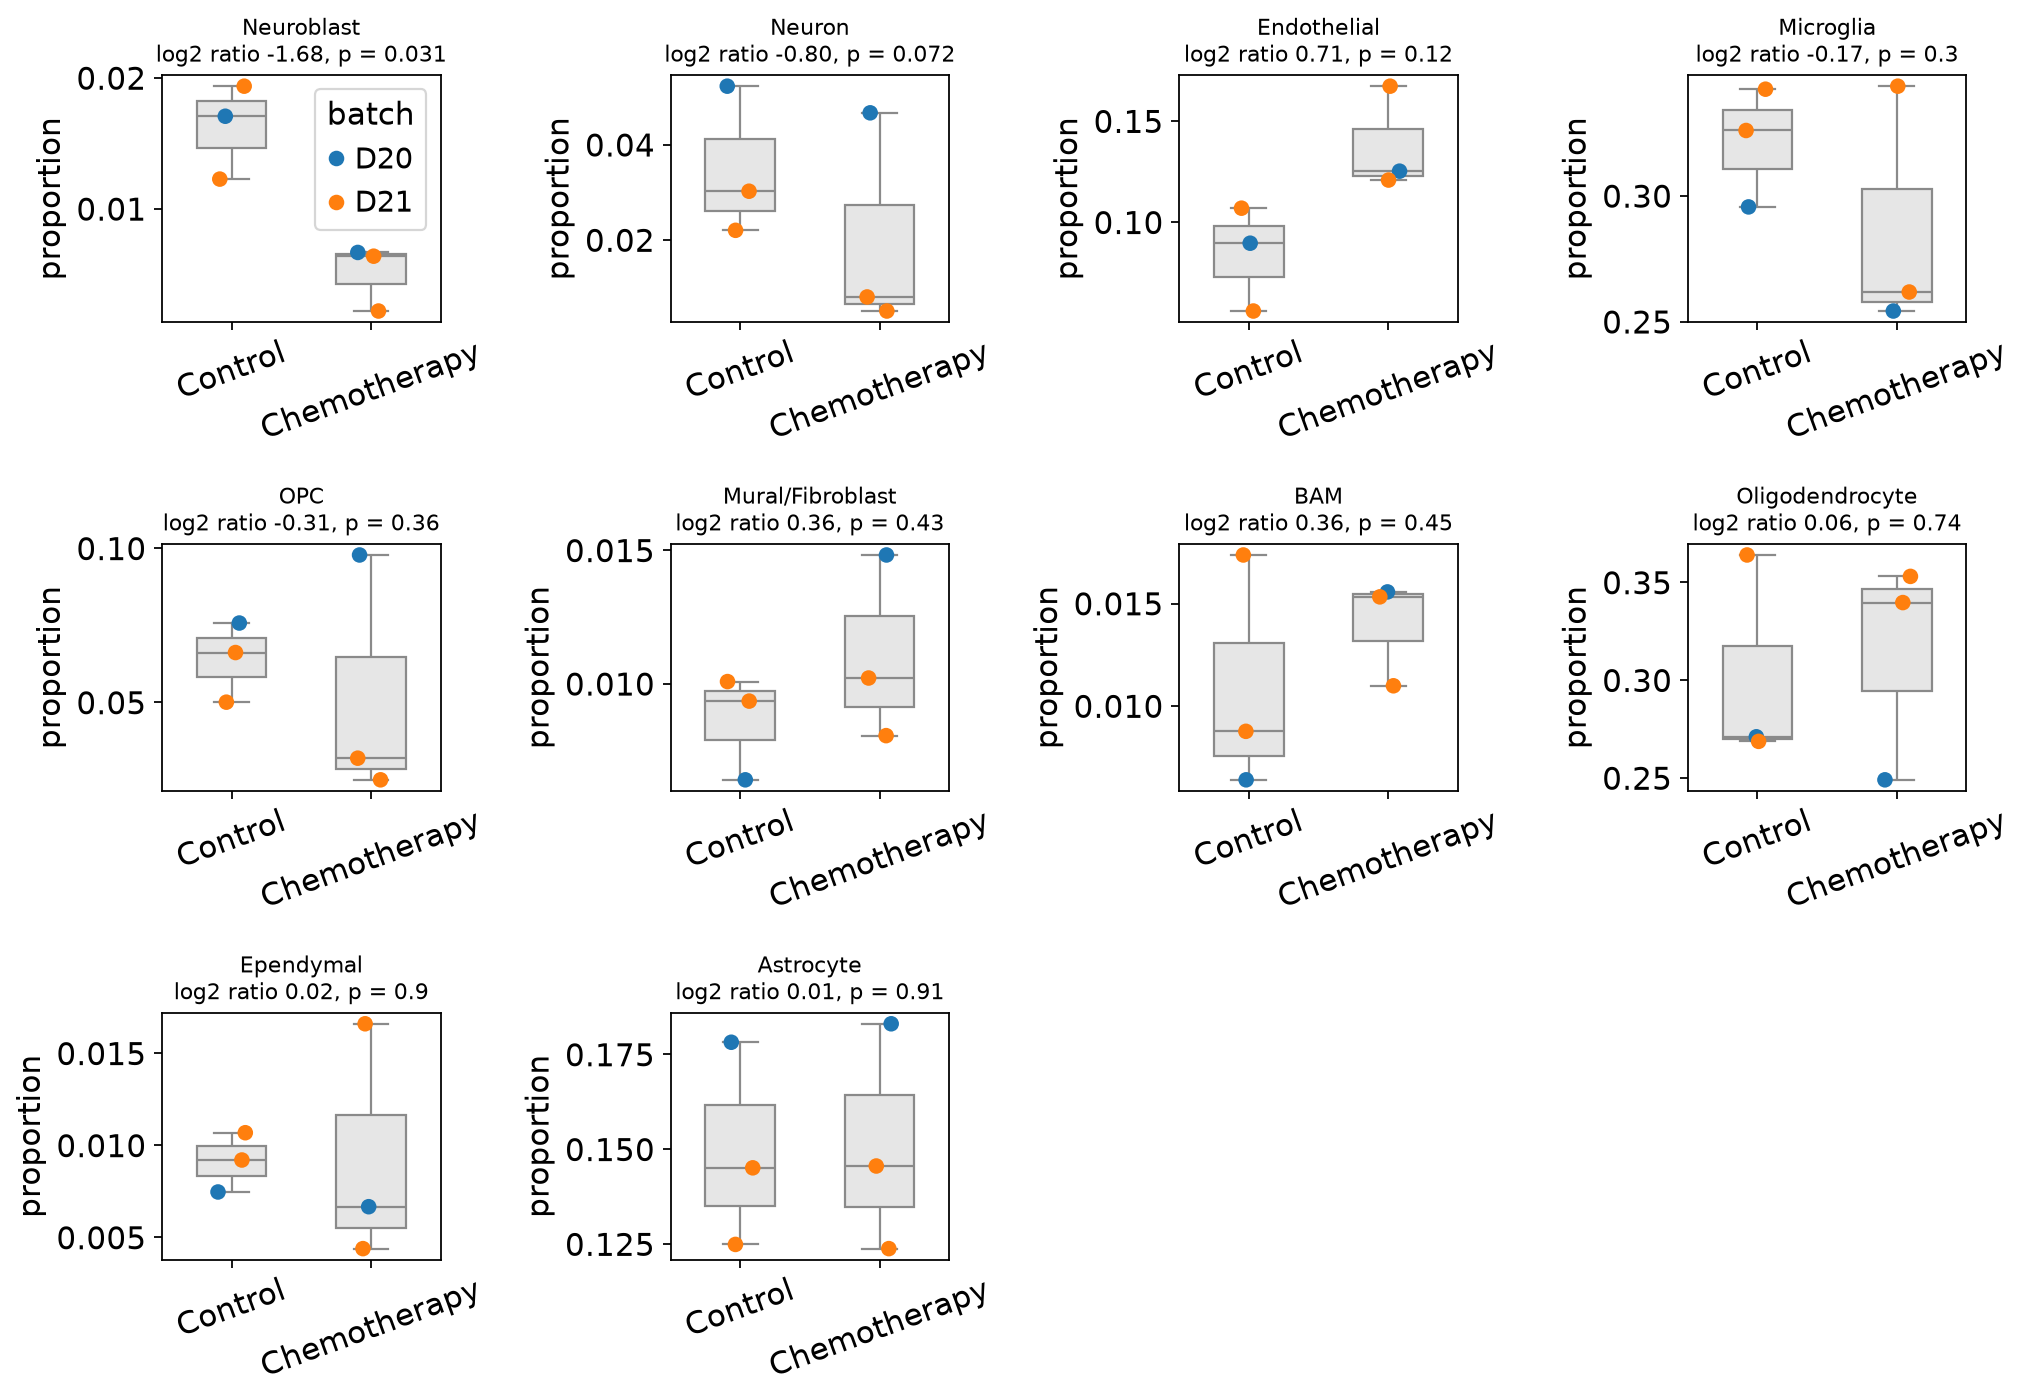

In [8]:
props_wo = counts_wo.div(counts_wo.sum(axis=1), axis=0)
long = (props_wo.reset_index().melt(id_vars="biosample", var_name="cell_type", value_name="proportion")
        .merge(meta, left_on="biosample", right_index=True))
types = list(res_wo.index)
ncol = 4
nrow = int(np.ceil(len(types) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3 * nrow))
for ax, ct in zip(axes.flat, types):
    d = long[long["cell_type"] == ct]
    sns.boxplot(d, x="condition", y="proportion", ax=ax, color="0.9", showfliers=False, width=0.5)
    sns.stripplot(d, x="condition", y="proportion", hue="batch", ax=ax, size=7, jitter=0.1, legend=ax is axes.flat[0])
    r = res_wo.loc[ct]
    ax.set_title(f"{ct}\nlog2 ratio {r['log2_ratio']:.2f}, p = {r['pval']:.2g}", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("proportion"); ax.grid(False)
    ax.tick_params(axis="x", labelrotation=20)
for ax in list(axes.flat)[len(types):]:
    ax.remove()
fig.tight_layout()
scu.save_fig(fig, cfg, "04_proportions_by_condition")
plt.show()

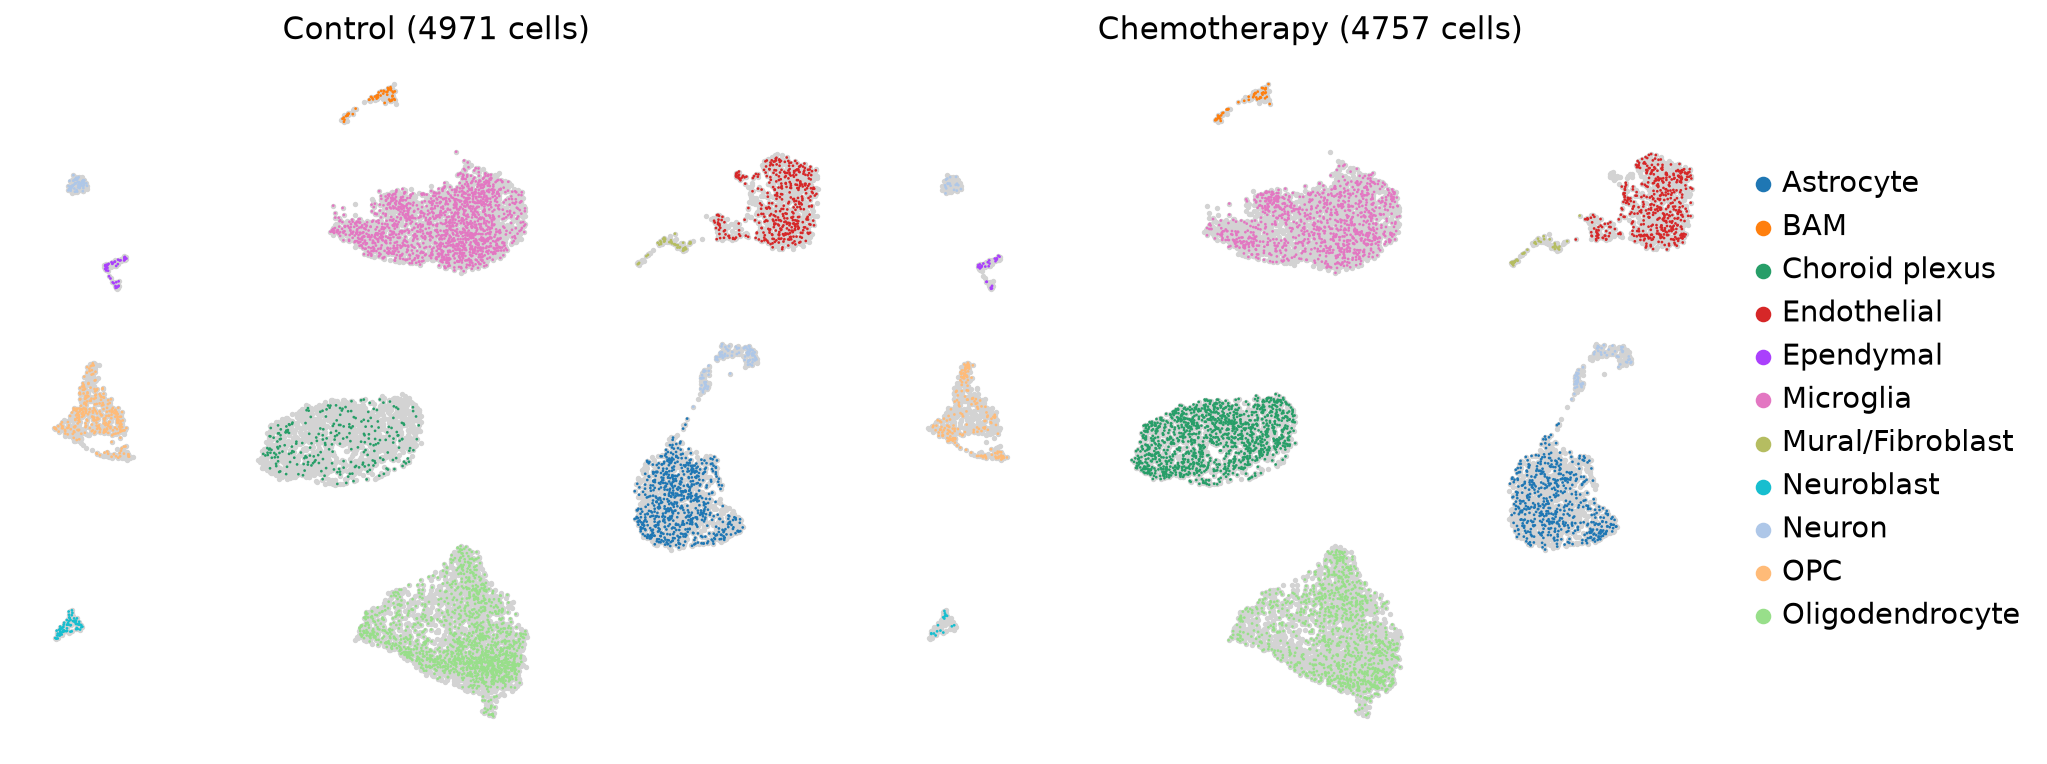

In [9]:
# UMAP split by condition: cells of one condition coloured, the rest in grey
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
xy = adata.obsm["X_umap"]
for ax, cond in zip(axes, meta["condition"].cat.categories):
    ax.scatter(xy[:, 0], xy[:, 1], s=2, c="lightgrey", rasterized=True)
    sc.pl.umap(adata[adata.obs["condition"] == cond], color="cell_type", ax=ax, show=False, size=6,
               title=f"{cond} ({(adata.obs['condition'] == cond).sum()} cells)",
               legend_loc="right margin" if ax is axes[-1] else None)
fig.tight_layout()
scu.save_fig(fig, cfg, "04_umap_by_condition")
plt.show()

In [10]:
del adata
_ = gc.collect()